# Classification average precision across evaluation splits

Values are read from the exports of notebook 02 (`model_results_long.csv` and `cv_fold_scores.csv`); no models are fitted. Each line represents a model. CV points show mean ? standard deviation across five folds; Validation and Test (June) are single scores. All values are percentages.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data.py').is_file())
RESULTS = ROOT / 'results/simple_to_complex'
LABELS = {'C0': 'No-skill baseline', 'C1': 'Logistic (all)', 'C2': 'Logistic (CV-stepwise)', 'C2B': 'Logistic (BIC)',
          'C4': 'Decision tree (tuned)', 'C3': 'Random Forest (tuned)', 'C3d': 'Random Forest (default)',
          'R0a': 'Median baseline', 'R0b': 'Olist promise', 'R1': 'OLS (all)', 'R2': 'OLS (CV-stepwise)',
          'R2B': 'OLS (BIC)', 'R4': 'Decision tree (tuned)', 'R3': 'Random Forest (tuned)', 'R3d': 'Random Forest (default)'}


def split_table(task, metric, codes, scale=1.0):
    """CV mean and SD, Validation and Test (June) for each model, from the notebook exports."""
    folds = pd.read_csv(RESULTS / task / 'cv_fold_scores.csv').groupby('model')[metric].agg(['mean', 'std'])
    single = pd.read_csv(RESULTS / task / 'model_results_long.csv').pivot(index='model', columns='split', values=metric)
    return pd.DataFrame([(c, LABELS[c], folds.loc[c, 'mean'] * scale, folds.loc[c, 'std'] * scale,
                          single.loc[c, 'Validation'] * scale, single.loc[c, 'June'] * scale) for c in codes],
                        columns=['Code', 'Model', 'CV', 'CV SD', 'Validation', 'Test (June)'])


ap_data = split_table('classification', 'avg_precision', ['C0', 'C1', 'C2', 'C2B', 'C4', 'C3', 'C3d'], scale=100)
ap_data.round(2)


,Code,Model,CV,CV SD,Validation,Test (June)
0,C0,No-skill baseline,8.37,3.51,10.06,1.89
1,C1,Logistic (all),11.75,2.89,24.63,7.67
2,C2,Logistic (CV-stepwise),12.42,4.21,17.36,3.36
3,C2B,Logistic (BIC),11.86,2.89,24.53,8.15
4,C4,Decision tree (tuned),10.79,3.94,16.76,3.33
5,C3,Random Forest (tuned),12.98,5.06,20.66,9.48
6,C3d,Random Forest (default),11.79,4.68,18.36,5.24


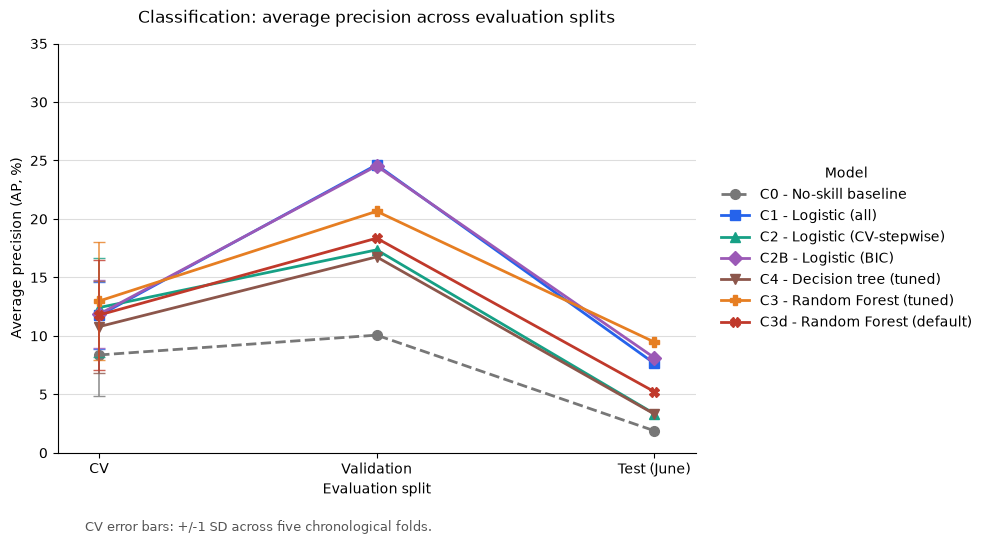

In [2]:
splits = ['CV', 'Validation', 'Test (June)']
colors = ['#777777', '#2563eb', '#16a085', '#9b59b6', '#8c564b', '#e67e22', '#c0392b']
markers = ['o', 's', '^', 'D', 'v', 'P', 'X']

with plt.rc_context({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'}):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for (_, row), color, marker in zip(ap_data.iterrows(), colors, markers):
        ax.plot(range(3), row[splits].to_numpy(dtype=float),
                color=color, marker=marker, markersize=7, linewidth=2,
                label=f"{row['Code']} - {row['Model']}",
                linestyle='--' if row['Code'] == 'C0' else '-')
        ax.errorbar(0, row['CV'], yerr=row['CV SD'], color=color,
                    fmt='none', capsize=4, linewidth=1.2, alpha=0.8)
    ax.set_xticks(range(3), splits)
    ax.set_xlim(-0.15, 2.15)
    ax.set_ylim(0, 35)
    ax.set_yticks(range(0, 36, 5))
    ax.set_xlabel('Evaluation split')
    ax.set_ylabel('Average precision (AP, %)')
    ax.set_title('Classification: average precision across evaluation splits', pad=15)
    ax.grid(axis='y', color='#dddddd', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(title='Model', loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.text(0.09, 0.025, 'CV error bars: +/-1 SD across five chronological folds.',
             fontsize=9, color='#555555')
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    output_path = RESULTS / 'figures/classification_ap_by_split.png'
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=200, bbox_inches='tight')
    plt.show()


## Regression RMSE across evaluation splits

Values are read from the exports of notebook 03 (`model_results_long.csv` and `cv_fold_scores.csv`). Lower RMSE is better. CV error bars show mean +/- one standard deviation across five chronological folds. No models are fitted.

In [3]:
rmse_data = split_table('regression', 'rmse', ['R0a', 'R0b', 'R1', 'R2', 'R2B', 'R4', 'R3', 'R3d'])
rmse_data.round(3)


,Code,Model,CV,CV SD,Validation,Test (June)
0,R0a,Median baseline,9.265,1.022,9.864,11.688
1,R0b,Olist promise,14.255,1.237,13.550,20.888
2,R1,OLS (all),8.651,1.349,8.205,7.369
3,R2,OLS (CV-stepwise),8.614,1.163,8.926,9.373
4,R2B,OLS (BIC),8.635,1.371,8.204,7.374
5,R4,Decision tree (tuned),8.648,1.114,9.013,9.598
6,R3,Random Forest (tuned),8.310,0.934,8.397,7.953
7,R3d,Random Forest (default),8.710,1.014,8.556,8.393


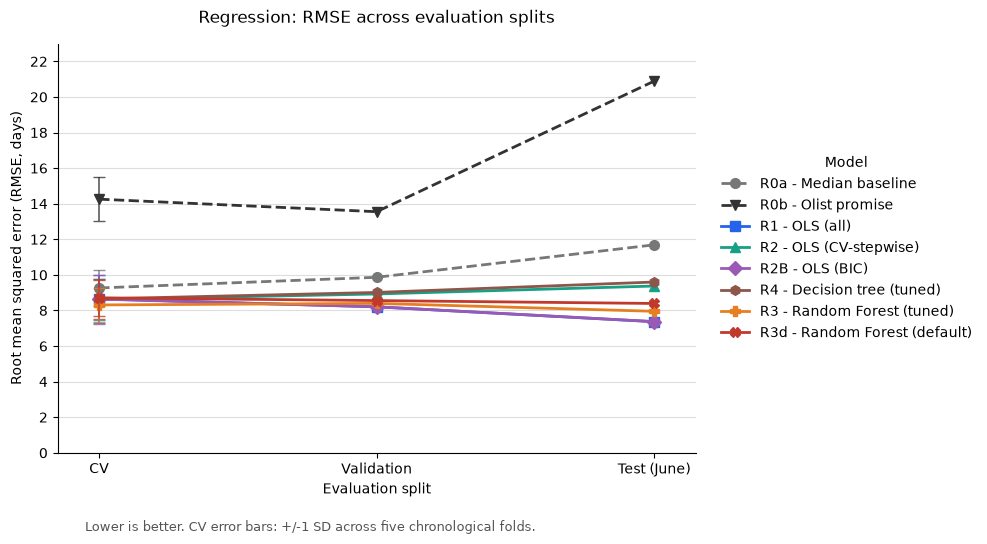

In [4]:
splits = ['CV', 'Validation', 'Test (June)']
rmse_colors = ['#777777', '#333333', '#2563eb', '#16a085', '#9b59b6', '#8c564b', '#e67e22', '#c0392b']
rmse_markers = ['o', 'v', 's', '^', 'D', 'h', 'P', 'X']

with plt.rc_context({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'}):
    rmse_fig, rmse_ax = plt.subplots(figsize=(10, 5.5))
    for (_, row), color, marker in zip(rmse_data.iterrows(), rmse_colors, rmse_markers):
        rmse_ax.plot(range(3), row[splits].to_numpy(dtype=float),
                     color=color, marker=marker, markersize=7, linewidth=2,
                     label=f"{row['Code']} - {row['Model']}",
                     linestyle='--' if row['Code'] in ('R0a', 'R0b') else '-')
        rmse_ax.errorbar(0, row['CV'], yerr=row['CV SD'], color=color,
                         fmt='none', capsize=4, linewidth=1.2, alpha=0.8)
    rmse_ax.set_xticks(range(3), splits)
    rmse_ax.set_xlim(-0.15, 2.15)
    rmse_ax.set_ylim(0, 23)
    rmse_ax.set_yticks(range(0, 23, 2))
    rmse_ax.set_xlabel('Evaluation split')
    rmse_ax.set_ylabel('Root mean squared error (RMSE, days)')
    rmse_ax.set_title('Regression: RMSE across evaluation splits', pad=15)
    rmse_ax.grid(axis='y', color='#dddddd', linewidth=0.8)
    rmse_ax.set_axisbelow(True)
    rmse_ax.legend(title='Model', loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
    rmse_fig.text(0.09, 0.025, 'Lower is better. CV error bars: +/-1 SD across five chronological folds.',
                  fontsize=9, color='#555555')
    rmse_fig.tight_layout(rect=(0, 0.06, 1, 1))
    rmse_output_path = RESULTS / 'figures/regression_rmse_by_split.png'
    rmse_output_path.parent.mkdir(parents=True, exist_ok=True)
    rmse_fig.savefig(rmse_output_path, dpi=200, bbox_inches='tight')
    plt.show()
